In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [4]:
df = pd.read_csv(r"C:\Users\DELL\Downloads\app_user_behavior_dataset.csv")

# missing value handling

In [5]:
df['rating_given'] = df['rating_given'].fillna(df['rating_given'].median())

In [4]:
df.isnull().sum()

user_id                          0
age                              0
gender                           0
country                          0
device_type                      0
app_version                      0
sessions_per_week                0
avg_session_duration_min         0
daily_active_minutes             0
feature_clicks_per_session       0
notifications_opened_per_week    0
in_app_search_count              0
pages_viewed_per_session         0
crash_events_last_30_days        0
support_tickets_raised           0
days_since_last_login            0
subscription_type                0
ads_clicked_last_30_days         0
content_downloads                0
social_shares                    0
rating_given                     0
churn_risk_score                 0
engagement_score                 0
account_age_days                 0
marketing_source                 0
dtype: int64

In [5]:
df['rating_given'].value_counts

<bound method IndexOpsMixin.value_counts of 0        4.0
1        3.0
2        2.0
3        3.0
4        5.0
        ... 
49995    4.0
49996    5.0
49997    1.0
49998    4.0
49999    4.0
Name: rating_given, Length: 50000, dtype: float64>

# Feature engineering

In [6]:
behavior_features = [
    'sessions_per_week',
    'avg_session_duration_min',
    'daily_active_minutes',
    'feature_clicks_per_session',
    'notifications_opened_per_week',
    'in_app_search_count',
    'pages_viewed_per_session',
    'days_since_last_login',
    'content_downloads',
    'social_shares',
    'churn_risk_score',
    'engagement_score'
]

X = df[behavior_features].copy()

In [7]:
X.head

<bound method NDFrame.head of        sessions_per_week  avg_session_duration_min  daily_active_minutes  \
0                      5                      3.41                 52.71   
1                      8                     24.44                 42.03   
2                     12                      5.34                 76.69   
3                      5                      3.98                 65.38   
4                     10                     12.85                 57.06   
...                  ...                       ...                   ...   
49995                 10                      8.68                 70.21   
49996                  6                      3.30                 41.51   
49997                  6                     21.67                 58.00   
49998                 13                     14.29                 37.93   
49999                  9                     20.57                 24.51   

       feature_clicks_per_session  notifications_opened_p

# Data scaling

In [2]:
scaler = StandardScaler()

In [8]:
X_scaled = scaler.fit_transform(X)

In [11]:
print("Scaled Data Shape:", X_scaled.shape)
print("\nFirst row before scaling:")
print(X.iloc[0].values)

print("\nFirst row after scaling:")
print(np.round(X_scaled[0], 2))

Scaled Data Shape: (50000, 12)

First row before scaling:
[ 5.    3.41 52.71 13.    5.    8.    8.   20.    5.    2.    0.31 55.79]

First row after scaling:
[-1.06 -1.09  0.39  0.28  0.    2.   -0.86 -0.16  1.15 -0.   -0.66 -0.62]


# Elbow method

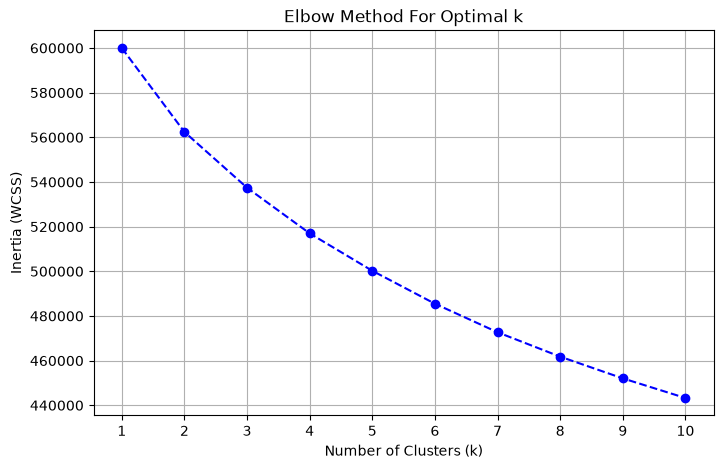

In [13]:
inertia = []
k_range = range(1, 11)

# 2. k = 1 to 10 varai K-Means run panrom
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

# 3. Elbow Curve plot panrom
plt.figure(figsize=(8, 5))
plt.plot(k_range, inertia, marker='o', linestyle='--', color='b')
plt.title('Elbow Method For Optimal k')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia (WCSS)')
plt.xticks(k_range)
plt.grid(True)
plt.show()

# K-means training

In [14]:
# 1. Train K-Means with k = 4
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_scaled)

# 2. Count of users in each cluster
print("--- USER COUNT PER CLUSTER ---")
print(df['Cluster'].value_counts().sort_index())

# 3. Cluster Profiling (Average of key behavioral metrics)
key_metrics = [
    'sessions_per_week',
    'avg_session_duration_min',
    'daily_active_minutes',
    'feature_clicks_per_session',
    'days_since_last_login',
    'churn_risk_score',
    'engagement_score'
]

cluster_profile = df.groupby('Cluster')[key_metrics].mean().round(2)

print("\n--- CLUSTER BEHAVIORAL PROFILE (AVERAGES) ---")
display(cluster_profile)

--- USER COUNT PER CLUSTER ---
Cluster
0    10487
1     7300
2    16080
3    16133
Name: count, dtype: int64

--- CLUSTER BEHAVIORAL PROFILE (AVERAGES) ---


,sessions_per_week,avg_session_duration_min,daily_active_minutes,feature_clicks_per_session,days_since_last_login,churn_risk_score,engagement_score
Cluster,,,,,,,
0,8.02,11.07,45.07,11.93,22.00,0.5,65.30
1,8.05,29.31,45.12,11.94,21.87,0.5,65.10
2,7.99,10.13,45.25,12.06,22.18,0.5,64.84
3,7.98,10.20,45.16,12.06,22.00,0.5,64.73


In [15]:
from sklearn.decomposition import PCA

# 1. PCA use panni top 3 principal components edukkirom
pca = PCA(n_components=3, random_state=42)
X_pca = pca.fit_transform(X_scaled)

print(f"Explained Variance Ratio by 3 components: {pca.explained_variance_ratio_.sum():.2%}")

# 2. PCA data moolama K-Means (k=4) fit panrom
kmeans_pca = KMeans(n_clusters=4, random_state=42, n_init=10)
df['Cluster'] = kmeans_pca.fit_predict(X_pca)

# 3. User counts per cluster
print("\n--- REFINED USER COUNT PER CLUSTER ---")
print(df['Cluster'].value_counts().sort_index())

# 4. Profile checking
key_metrics = [
    'sessions_per_week',
    'avg_session_duration_min',
    'daily_active_minutes',
    'feature_clicks_per_session',
    'days_since_last_login',
    'churn_risk_score',
    'engagement_score'
]

refined_profile = df.groupby('Cluster')[key_metrics].mean().round(2)
print("\n--- REFINED CLUSTER BEHAVIORAL PROFILE ---")
display(refined_profile)

Explained Variance Ratio by 3 components: 25.42%

--- REFINED USER COUNT PER CLUSTER ---
Cluster
0    11072
1    13086
2    13064
3    12778
Name: count, dtype: int64

--- REFINED CLUSTER BEHAVIORAL PROFILE ---


,sessions_per_week,avg_session_duration_min,daily_active_minutes,feature_clicks_per_session,days_since_last_login,churn_risk_score,engagement_score
Cluster,,,,,,,
0,7.86,21.26,43.24,11.37,17.58,0.38,67.20
1,9.33,11.50,47.09,12.82,30.52,0.39,61.50
2,7.55,10.16,37.63,10.79,20.21,0.57,63.33
3,7.21,10.87,52.56,12.99,19.09,0.64,68.15


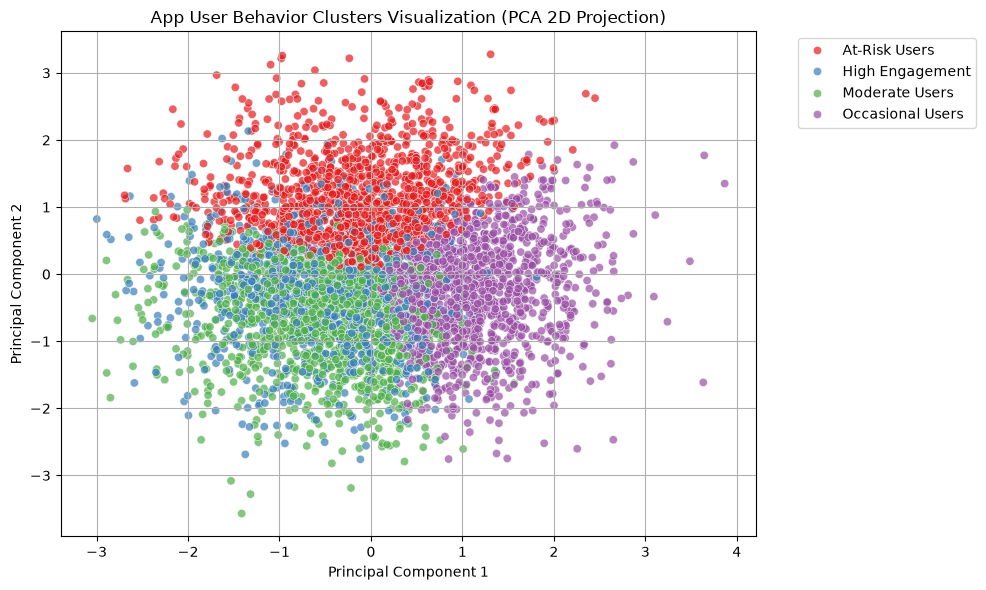

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Map cluster names to dataframe
cluster_labels = {
    0: 'High Engagement',
    1: 'Occasional Users',
    2: 'Moderate Users',
    3: 'At-Risk Users'
}
df['Cluster_Segment'] = df['Cluster'].map(cluster_labels)

# 2. PCA 2D coordinates dataframe
pca_df = pd.DataFrame(X_pca[:, :2], columns=['PCA1', 'PCA2'])
pca_df['Segment'] = df['Cluster_Segment']

# 3. 2D Scatter Plot
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x='PCA1', 
    y='PCA2', 
    hue='Segment', 
    data=pca_df.sample(5000, random_state=42), # 5000 sample points for clear, fast visual
    palette='Set1', 
    alpha=0.7
)
plt.title('App User Behavior Clusters Visualization (PCA 2D Projection)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()

In [17]:
# 1. Output file export panrom
output_columns = [
    'user_id', 'age', 'gender', 'country', 'device_type', 
    'sessions_per_week', 'avg_session_duration_min', 'daily_active_minutes',
    'churn_risk_score', 'engagement_score', 'Cluster', 'Cluster_Segment'
]

df[output_columns].to_csv('segmented_app_users.csv', index=False)
print("Segmented dataset exported successfully as 'segmented_app_users.csv'!")

Segmented dataset exported successfully as 'segmented_app_users.csv'!
